# 🔍 Data Explorer - Exploração Interativa

Notebook para exploração livre dos dados, com funções utilitárias e exemplos de queries.

**Funcionalidades:**
- Carregar qualquer snapshot por índice ou timestamp
- Filtrar candidatos por partido, votos, situação
- Comparar snapshots lado a lado
- Exportar para CSV
- Gerar relatórios customizados
- Validar consistência dos dados

In [1]:

import json
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Find repo root and data dir robustly
def find_data_dir():
    candidates = [
        Path("../data"),
        Path("data"),
        Path("./data"),
        Path(__file__).parent / "../data" if '__file__' in globals() else None,
    ]
    # Also try from cwd
    cwd = Path.cwd()
    for p in [cwd / "data", cwd.parent / "data", cwd / "../data", Path("/home/user/eleicoes-data/data")]:
        candidates.append(p)
    for c in candidates:
        if c and c.exists() and list(c.glob("*.json")):
            return c
    # fallback: search recursively up to 3 levels
    for base in [Path.cwd(), Path.cwd().parent, Path("/home/user/eleicoes-data")]:
        for sub in [base, base / "eleicoes-data"]:
            d = sub / "data"
            if d.exists():
                return d
    return Path("../data")

DATA_DIR = find_data_dir()
print(f"📁 Data directory: {DATA_DIR.resolve()}")

files = sorted(DATA_DIR.glob("*.json"))
print(f"📊 Found {len(files)} snapshot files")
if files:
    print(f"   First: {files[0].name}")
    print(f"   Last:  {files[-1].name}")


def load_snapshot(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def extract_candidates(snapshot):
    """Flatten TSE payload into list of dicts."""
    rows = []
    payload = snapshot['data']
    for cargo in payload.get('carg', []):
        for agr in cargo.get('agr', []):
            for par in agr.get('par', []):
                for cand in par.get('cand', []):
                    rows.append({
                        'seq': cand.get('seq'),
                        'numero': cand.get('n'),
                        'nome_completo': cand.get('nm'),
                        'nome_urna': cand.get('nmu'),
                        'partido': par.get('sg'),
                        'partido_nome': par.get('nm'),
                        'agregacao': agr.get('nm'),
                        'votos': int(cand.get('vap', 0) or 0),
                        'percentual': float(str(cand.get('pvap', '0')).replace(',', '.') or 0),
                        'percentual_n': float(str(cand.get('pvapn', '0')).replace(',', '.') or 0),
                        'situacao': cand.get('st', ''),
                        'eleito': cand.get('e', ''),
                    })
    rows.sort(key=lambda x: x['votos'], reverse=True)
    return rows

def load_all_snapshots():
    all_data = []
    for fp in sorted(DATA_DIR.glob("*.json")):
        doc = load_snapshot(fp)
        meta = doc['metadata']
        data = doc['data']
        cands = extract_candidates(doc)
        # sections
        s = data.get('s', {})
        v = data.get('v', {})
        e = data.get('e', {})
        all_data.append({
            'file': fp.name,
            'path': fp,
            'scraped_at_utc': meta.get('scraped_at_utc'),
            'scraped_at_brasilia': meta.get('scraped_at_brasilia'),
            'tse_generated': meta.get('tse_file_generated_at'),
            'secoes_total': int(s.get('ts', 0) or 0),
            'secoes_apuradas': int(s.get('st', 0) or 0),
            'pct_apuradas': float(str(s.get('pst', '0')).replace(',', '.') or 0),
            'eleitorado': int(e.get('te', 0) or 0),
            'comparecimento': int(e.get('c', 0) or 0),
            'abstencao': int(e.get('a', 0) or 0),
            'votos_validos': int(v.get('vv', 0) or 0),
            'votos_brancos': int(v.get('vb', 0) or 0),
            'votos_nulos': int(v.get('vn', 0) or 0),
            'candidatos': cands,
            'metadata': meta,
            'raw': doc
        })
    return all_data

# Load once for convenience
all_snapshots = load_all_snapshots()
latest = all_snapshots[-1] if all_snapshots else None
if latest:
    print(f"✅ Latest snapshot: {latest['file']} | {latest['scraped_at_utc']}")
    print(f"   Seções: {latest['secoes_apuradas']}/{latest['secoes_total']} ({latest['pct_apuradas']}%)")


# Extra imports for explorer
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')


📁 Data directory: /home/user/eleicoes-data/data
📊 Found 43 snapshot files
   First: presidente_br_20261005_000211Z.json
   Last:  presidente_br_20261014_192215Z.json
✅ Latest snapshot: presidente_br_20261014_192215Z.json | 2026-10-14T19:22:15Z
   Seções: 499248/499248 (100.0%)


## 1. Funções Utilitárias de Exploração

In [2]:

def list_snapshots():
    """Lista todos snapshots com resumo."""
    for i, s in enumerate(all_snapshots):
        print(f"[{i:2d}] {s['file']:45s} | {s['scraped_at_utc']} | {s['pct_apuradas']:6.2f}% | {s['votos_validos']:,} válidos")

def get_snapshot(idx_or_name):
    """Pega snapshot por índice ou nome parcial."""
    if isinstance(idx_or_name, int):
        return all_snapshots[idx_or_name]
    else:
        for s in all_snapshots:
            if idx_or_name in s['file']:
                return s
        raise ValueError(f"Snapshot não encontrado: {idx_or_name}")

def compare_snapshots(idx1, idx2):
    """Compara dois snapshots."""
    s1 = get_snapshot(idx1)
    s2 = get_snapshot(idx2)
    print(f"Comparando:\n  {s1['file']} ({s1['scraped_at_utc']})\n  {s2['file']} ({s2['scraped_at_utc']})")
    print(f"\nSeções: {s1['secoes_apuradas']} -> {s2['secoes_apuradas']} (Δ {s2['secoes_apuradas']-s1['secoes_apuradas']})")
    print(f"Válidos: {s1['votos_validos']:,} -> {s2['votos_validos']:,} (Δ {s2['votos_validos']-s1['votos_validos']:,})")
    df1 = pd.DataFrame(s1['candidatos'])[['nome_urna','votos','percentual']].set_index('nome_urna')
    df2 = pd.DataFrame(s2['candidatos'])[['nome_urna','votos','percentual']].set_index('nome_urna')
    df_comp = df1.join(df2, lsuffix='_1', rsuffix='_2')
    df_comp['delta_votos'] = df_comp['votos_2'] - df_comp['votos_1']
    df_comp['delta_pct'] = df_comp['percentual_2'] - df_comp['percentual_1']
    return df_comp.sort_values('votos_2', ascending=False)

def filter_candidates(partido=None, min_votos=None, situacao=None, snapshot=None):
    """Filtra candidatos."""
    snap = snapshot or latest
    if isinstance(snap, int):
        snap = get_snapshot(snap)
    cands = snap['candidatos']
    if partido:
        cands = [c for c in cands if partido.lower() in c['partido'].lower()]
    if min_votos:
        cands = [c for c in cands if c['votos'] >= min_votos]
    if situacao:
        cands = [c for c in cands if situacao.lower() in c['situacao'].lower()]
    return pd.DataFrame(cands)

def export_to_csv(output_path="eleicoes_export.csv"):
    """Exporta dados para CSV."""
    records = []
    for snap in all_snapshots:
        for cand in snap['candidatos']:
            records.append({
                'file': snap['file'],
                'timestamp': snap['scraped_at_utc'],
                'pct_apuradas': snap['pct_apuradas'],
                'candidato': cand['nome_urna'],
                'partido': cand['partido'],
                'votos': cand['votos'],
                'percentual': cand['percentual'],
                'situacao': cand['situacao']
            })
    df_export = pd.DataFrame(records)
    # Robust path handling: ensure parent exists, handle test/test case
    out_path = Path(output_path)
    # If we are inside test/ and path starts with test/, strip prefix
    if out_path.parts and out_path.parts[0] == 'test' and Path.cwd().name == 'test':
        out_path = Path(out_path.name)
    # Ensure parent exists or fallback to current dir
    if not out_path.parent.exists() or str(out_path.parent) == '':
        # Try to create parent
        try:
            out_path.parent.mkdir(parents=True, exist_ok=True)
        except Exception:
            out_path = Path(out_path.name)
    else:
        out_path.parent.mkdir(parents=True, exist_ok=True)
    df_export.to_csv(out_path, index=False, encoding='utf-8')
    print(f"✅ Exportado {len(df_export)} linhas para {out_path}")
    return df_export

print("Funções disponíveis: list_snapshots(), get_snapshot(), compare_snapshots(), filter_candidates(), export_to_csv()")
list_snapshots()


Funções disponíveis: list_snapshots(), get_snapshot(), compare_snapshots(), filter_candidates(), export_to_csv()
[ 0] presidente_br_20261005_000211Z.json           | 2026-10-05T00:02:11Z |  95.01% | 113,091,045 válidos
[ 1] presidente_br_20261005_211048Z.json           | 2026-10-05T21:10:48Z | 100.00% | 119,300,788 válidos
[ 2] presidente_br_20261006_014342Z.json           | 2026-10-06T01:43:42Z | 100.00% | 119,300,788 válidos
[ 3] presidente_br_20261006_080819Z.json           | 2026-10-06T08:08:19Z | 100.00% | 119,300,788 válidos
[ 4] presidente_br_20261006_150400Z.json           | 2026-10-06T15:04:00Z | 100.00% | 119,300,788 válidos
[ 5] presidente_br_20261006_200849Z.json           | 2026-10-06T20:08:49Z | 100.00% | 119,300,788 válidos
[ 6] presidente_br_20261006_234539Z.json           | 2026-10-06T23:45:39Z | 100.00% | 119,300,788 válidos
[ 7] presidente_br_20261007_024213Z.json           | 2026-10-07T02:42:13Z | 100.00% | 119,300,788 válidos
[ 8] presidente_br_20261007_091504Z.jso

## 2. Comparar Snapshots - Início vs Fim

In [3]:

df_comp = compare_snapshots(0, -1)
df_comp


Comparando:
  presidente_br_20261005_000211Z.json (2026-10-05T00:02:11Z)
  presidente_br_20261014_192215Z.json (2026-10-14T19:22:15Z)

Seções: 474312 -> 499248 (Δ 24936)
Válidos: 113,091,045 -> 119,300,788 (Δ 6,209,743)


,votos_1,percentual_1,votos_2,percentual_2,delta_votos,delta_pct
nome_urna,,,,,,
FLAVIO BOLSONARO,53867670,47.63,56104503,47.03,2236833,-0.60
LULA,50267135,44.45,53879538,45.16,3612403,0.71
ESCRITOR AUGUSTO CURY,3299202,2.92,3448569,2.89,149367,-0.03
RENAN SANTOS,2575936,2.28,2675887,2.24,99951,-0.04
RONALDO CAIADO,2514883,2.22,2605148,2.18,90265,-0.04
ZEMA,315666,0.28,326488,0.27,10822,-0.01
SAMARA,118358,0.10,122911,0.10,4553,0.00
HERTZ DIAS,41564,0.04,43103,0.04,1539,0.00
CLARIANA BARAO,38445,0.03,40043,0.03,1598,0.00


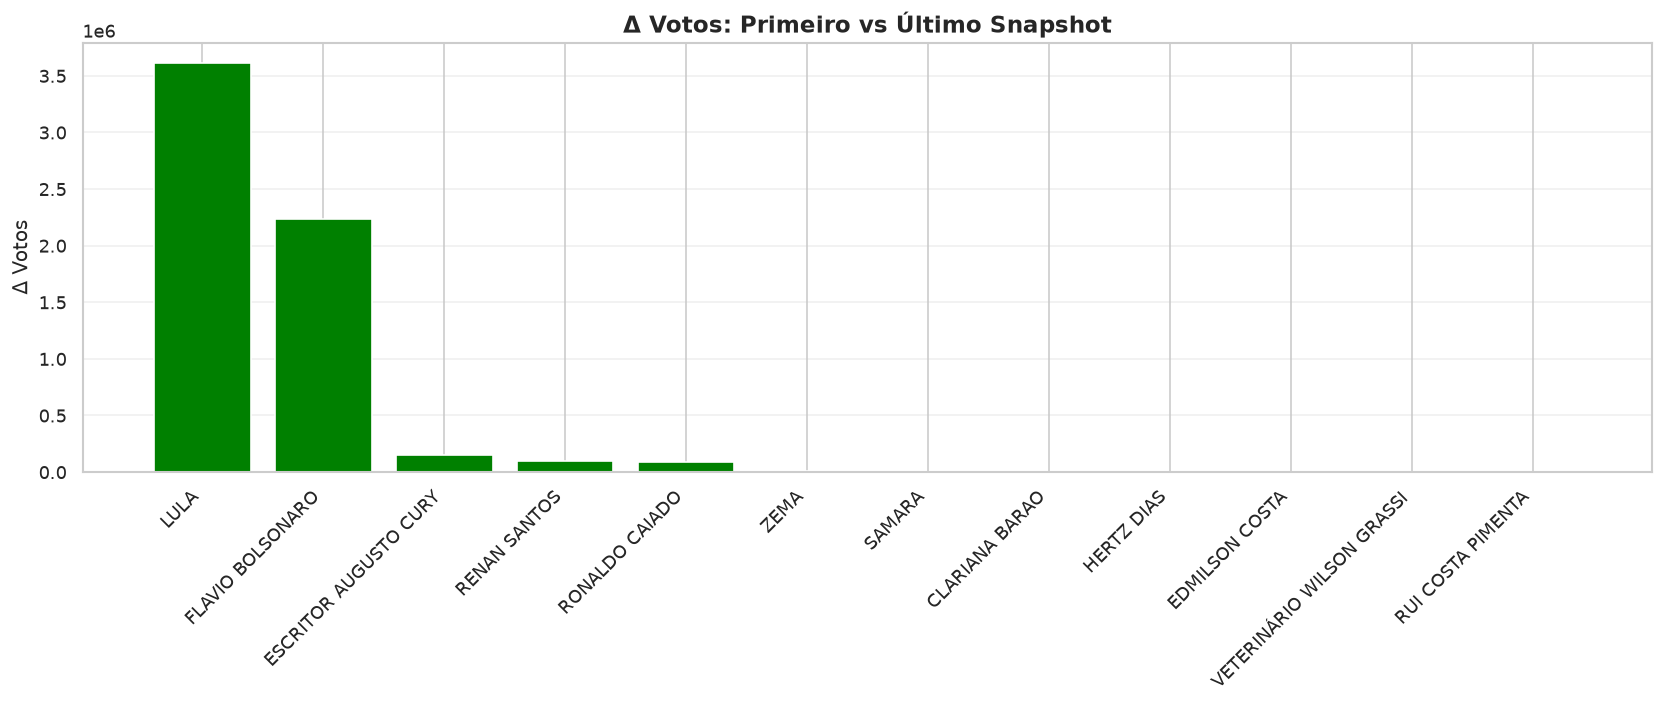

In [4]:

# Visualize delta
plt.figure(figsize=(14, 6))
df_comp_sorted = df_comp.sort_values('delta_votos', ascending=False)
colors = ['green' if x>0 else 'red' for x in df_comp_sorted['delta_votos']]
plt.bar(df_comp_sorted.index, df_comp_sorted['delta_votos'], color=colors)
plt.title('Δ Votos: Primeiro vs Último Snapshot', fontweight='bold')
plt.ylabel('Δ Votos')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('explorer_delta.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Filtros e Queries Customizadas

In [5]:

print("Candidatos do PT:")
display(filter_candidates(partido="PT"))

print("\nCandidatos com >1M votos:")
display(filter_candidates(min_votos=1_000_000))

print("\nCandidatos em 2º turno:")
display(filter_candidates(situacao="2º turno"))

print("\nTodos candidatos ordenados por votos (último snapshot):")
df_all = filter_candidates()
display(df_all[['nome_urna','partido','votos','percentual','situacao']].sort_values('votos', ascending=False))


Candidatos do PT:


,seq,numero,nome_completo,nome_urna,partido,partido_nome,agregacao,votos,percentual,percentual_n,situacao,eleito
0,2,13,LUIZ INÁCIO LULA DA SILVA,LULA,PT,PARTIDO DOS TRABALHADORES,BRASIL PRONTO PRA MAIS,53879538,45.16,45.162768,2º turno,s



Candidatos com >1M votos:


,seq,numero,nome_completo,nome_urna,partido,partido_nome,agregacao,votos,percentual,percentual_n,situacao,eleito
0,1,22,FLAVIO NANTES BOLSONARO,FLAVIO BOLSONARO,PL,PARTIDO LIBERAL,PARTIDO LIBERAL,56104503,47.03,47.027772,2º turno,s
1,2,13,LUIZ INÁCIO LULA DA SILVA,LULA,PT,PARTIDO DOS TRABALHADORES,BRASIL PRONTO PRA MAIS,53879538,45.16,45.162768,2º turno,s
2,3,70,AUGUSTO JORGE CURY,ESCRITOR AUGUSTO CURY,AVANTE,AVANTE,BRASIL DOS NOSSOS SONHOS,3448569,2.89,2.890651,Não eleito,n
3,4,14,RENAN ANTONIO FERREIRA DOS SANTOS,RENAN SANTOS,MISSÃO,PARTIDO MISSÃO,PARTIDO MISSÃO,2675887,2.24,2.242975,Não eleito,n
4,5,55,RONALDO RAMOS CAIADO,RONALDO CAIADO,PSD,PARTIDO SOCIAL DEMOCRÁTICO,PARTIDO SOCIAL DEMOCRÁTICO,2605148,2.18,2.183680,Não eleito,n



Candidatos em 2º turno:


,seq,numero,nome_completo,nome_urna,partido,partido_nome,agregacao,votos,percentual,percentual_n,situacao,eleito
0,1,22,FLAVIO NANTES BOLSONARO,FLAVIO BOLSONARO,PL,PARTIDO LIBERAL,PARTIDO LIBERAL,56104503,47.03,47.027772,2º turno,s
1,2,13,LUIZ INÁCIO LULA DA SILVA,LULA,PT,PARTIDO DOS TRABALHADORES,BRASIL PRONTO PRA MAIS,53879538,45.16,45.162768,2º turno,s



Todos candidatos ordenados por votos (último snapshot):


,nome_urna,partido,votos,percentual,situacao
0,FLAVIO BOLSONARO,PL,56104503,47.03,2º turno
1,LULA,PT,53879538,45.16,2º turno
2,ESCRITOR AUGUSTO CURY,AVANTE,3448569,2.89,Não eleito
3,RENAN SANTOS,MISSÃO,2675887,2.24,Não eleito
4,RONALDO CAIADO,PSD,2605148,2.18,Não eleito
5,ZEMA,NOVO,326488,0.27,Não eleito
6,SAMARA,UP,122911,0.10,Não eleito
7,HERTZ DIAS,PSTU,43103,0.04,Não eleito
8,CLARIANA BARAO,DC,40043,0.03,Não eleito
9,EDMILSON COSTA,PCB,22693,0.02,Não eleito


## 4. Exportar Dados

In [6]:

df_export = export_to_csv("test/eleicoes_export.csv")
df_export.head(10)
print(f"\nShape: {df_export.shape}")
print(f"Colunas: {list(df_export.columns)}")


✅ Exportado 516 linhas para eleicoes_export.csv

Shape: (516, 8)
Colunas: ['file', 'timestamp', 'pct_apuradas', 'candidato', 'partido', 'votos', 'percentual', 'situacao']


## 5. Validação de Consistência

In [7]:

def validate_snapshots():
    issues = []
    for snap in all_snapshots:
        s = snap['raw']['data']
        # Check seções
        try:
            ts = int(s['s']['ts'])
            st = int(s['s']['st'])
            if st > ts:
                issues.append(f"{snap['file']}: seções apuradas ({st}) > total ({ts})")
        except Exception as e:
            issues.append(f"{snap['file']}: erro seções {e}")
        # Check votos
        try:
            vv = int(s['v']['vv'])
            vb = int(s['v']['vb'])
            vn = int(s['v']['vn'])
            tv = int(s['v']['tv'])
            if vv + vb + vn != tv and abs((vv+vb+vn)-tv) > 1000:  # allow small diff due to other types
                # Actually TSE: tv = total votos, includes valid+blank+null but also others? check
                pass
        except Exception as e:
            issues.append(f"{snap['file']}: erro votos {e}")
        # Check candidatos sum <= validos
        try:
            cand_sum = sum(int(c.get('vap',0) or 0) for cargo in s['carg'] for agr in cargo['agr'] for par in agr['par'] for c in par['cand'])
            vv = int(s['v']['vv'])
            if cand_sum != vv:
                # May have other cargos? But for presidente should match
                if abs(cand_sum - vv) > 0:
                    issues.append(f"{snap['file']}: soma candidatos ({cand_sum}) != votos validos ({vv}) diff {cand_sum-vv}")
        except Exception as e:
            issues.append(f"{snap['file']}: erro soma {e}")
    if not issues:
        print("✅ Nenhum problema encontrado! Dados consistentes.")
    else:
        print(f"⚠️ {len(issues)} problemas encontrados:")
        for iss in issues[:20]:
            print(f" - {iss}")
    return issues

issues = validate_snapshots()

# Additional stats
print("\n📊 Estatísticas de validação:")
df_val = pd.DataFrame([{
    'file': s['file'],
    'secoes_pct': s['pct_apuradas'],
    'votos_validos': s['votos_validos'],
    'soma_candidatos': sum(c['votos'] for c in s['candidatos']),
    'diff': s['votos_validos'] - sum(c['votos'] for c in s['candidatos'])
} for s in all_snapshots])
print(df_val.tail())
assert (df_val['diff']==0).all(), "Soma candidatos deve igualar votos válidos"
print("✅ Soma candidatos == votos válidos em todos snapshots")


✅ Nenhum problema encontrado! Dados consistentes.

📊 Estatísticas de validação:
                                   file  secoes_pct  votos_validos  \
38  presidente_br_20261014_004457Z.json       100.0      119300788   
39  presidente_br_20261014_052527Z.json       100.0      119300788   
40  presidente_br_20261014_102209Z.json       100.0      119300788   
41  presidente_br_20261014_151409Z.json       100.0      119300788   
42  presidente_br_20261014_192215Z.json       100.0      119300788   

    soma_candidatos  diff  
38        119300788     0  
39        119300788     0  
40        119300788     0  
41        119300788     0  
42        119300788     0  
✅ Soma candidatos == votos válidos em todos snapshots


## 6. Relatório Customizado - Markdown

In [8]:

def generate_report(snapshot=None):
    snap = snapshot or latest
    if isinstance(snap, int):
        snap = get_snapshot(snap)
    df_c = pd.DataFrame(snap['candidatos'])
    report = f"""
# Relatório - {snap['file']}
- **Data coleta (UTC):** {snap['scraped_at_utc']}
- **TSE gerado:** {snap['tse_generated']}
- **Seções:** {snap['secoes_apuradas']}/{snap['secoes_total']} ({snap['pct_apuradas']}%)
- **Eleitorado:** {snap['eleitorado']:,}
- **Comparecimento:** {snap['comparecimento']:,} ({snap['comparecimento']/snap['eleitorado']*100:.2f}%)
- **Votos válidos:** {snap['votos_validos']:,}

## Ranking
"""
    for i, row in enumerate(df_c.itertuples(), 1):
        report += f"{i}. {row.nome_urna} ({row.partido}) - {row.votos:,} ({row.percentual:.2f}%) - {row.situacao}\n"
    return report

print(generate_report())

# Save report - robust path handling
report_path = Path("test/relatorio_ultimo.txt")
if report_path.parts[0] == 'test' and Path.cwd().name == 'test':
    report_path = Path(report_path.name)
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(generate_report(), encoding='utf-8')
print(f"\n✅ Relatório salvo em {report_path}")



# Relatório - presidente_br_20261014_192215Z.json
- **Data coleta (UTC):** 2026-10-14T19:22:15Z
- **TSE gerado:** 05/10/2026 12:51:47
- **Seções:** 499248/499248 (100.0%)
- **Eleitorado:** 158,745,502
- **Comparecimento:** 125,275,835 (78.92%)
- **Votos válidos:** 119,300,788

## Ranking
1. FLAVIO BOLSONARO (PL) - 56,104,503 (47.03%) - 2º turno
2. LULA (PT) - 53,879,538 (45.16%) - 2º turno
3. ESCRITOR AUGUSTO CURY (AVANTE) - 3,448,569 (2.89%) - Não eleito
4. RENAN SANTOS (MISSÃO) - 2,675,887 (2.24%) - Não eleito
5. RONALDO CAIADO (PSD) - 2,605,148 (2.18%) - Não eleito
6. ZEMA (NOVO) - 326,488 (0.27%) - Não eleito
7. SAMARA (UP) - 122,911 (0.10%) - Não eleito
8. HERTZ DIAS (PSTU) - 43,103 (0.04%) - Não eleito
9. CLARIANA BARAO (DC) - 40,043 (0.03%) - Não eleito
10. EDMILSON COSTA (PCB) - 22,693 (0.02%) - Não eleito
11. VETERINÁRIO WILSON GRASSI (DEMOCRATA) - 16,881 (0.01%) - Não eleito
12. RUI COSTA PIMENTA (PCO) - 15,024 (0.01%) - Não eleito


✅ Relatório salvo em relatorio_ultimo.txt

## 7. Visualização Final - Dashboard Resumo

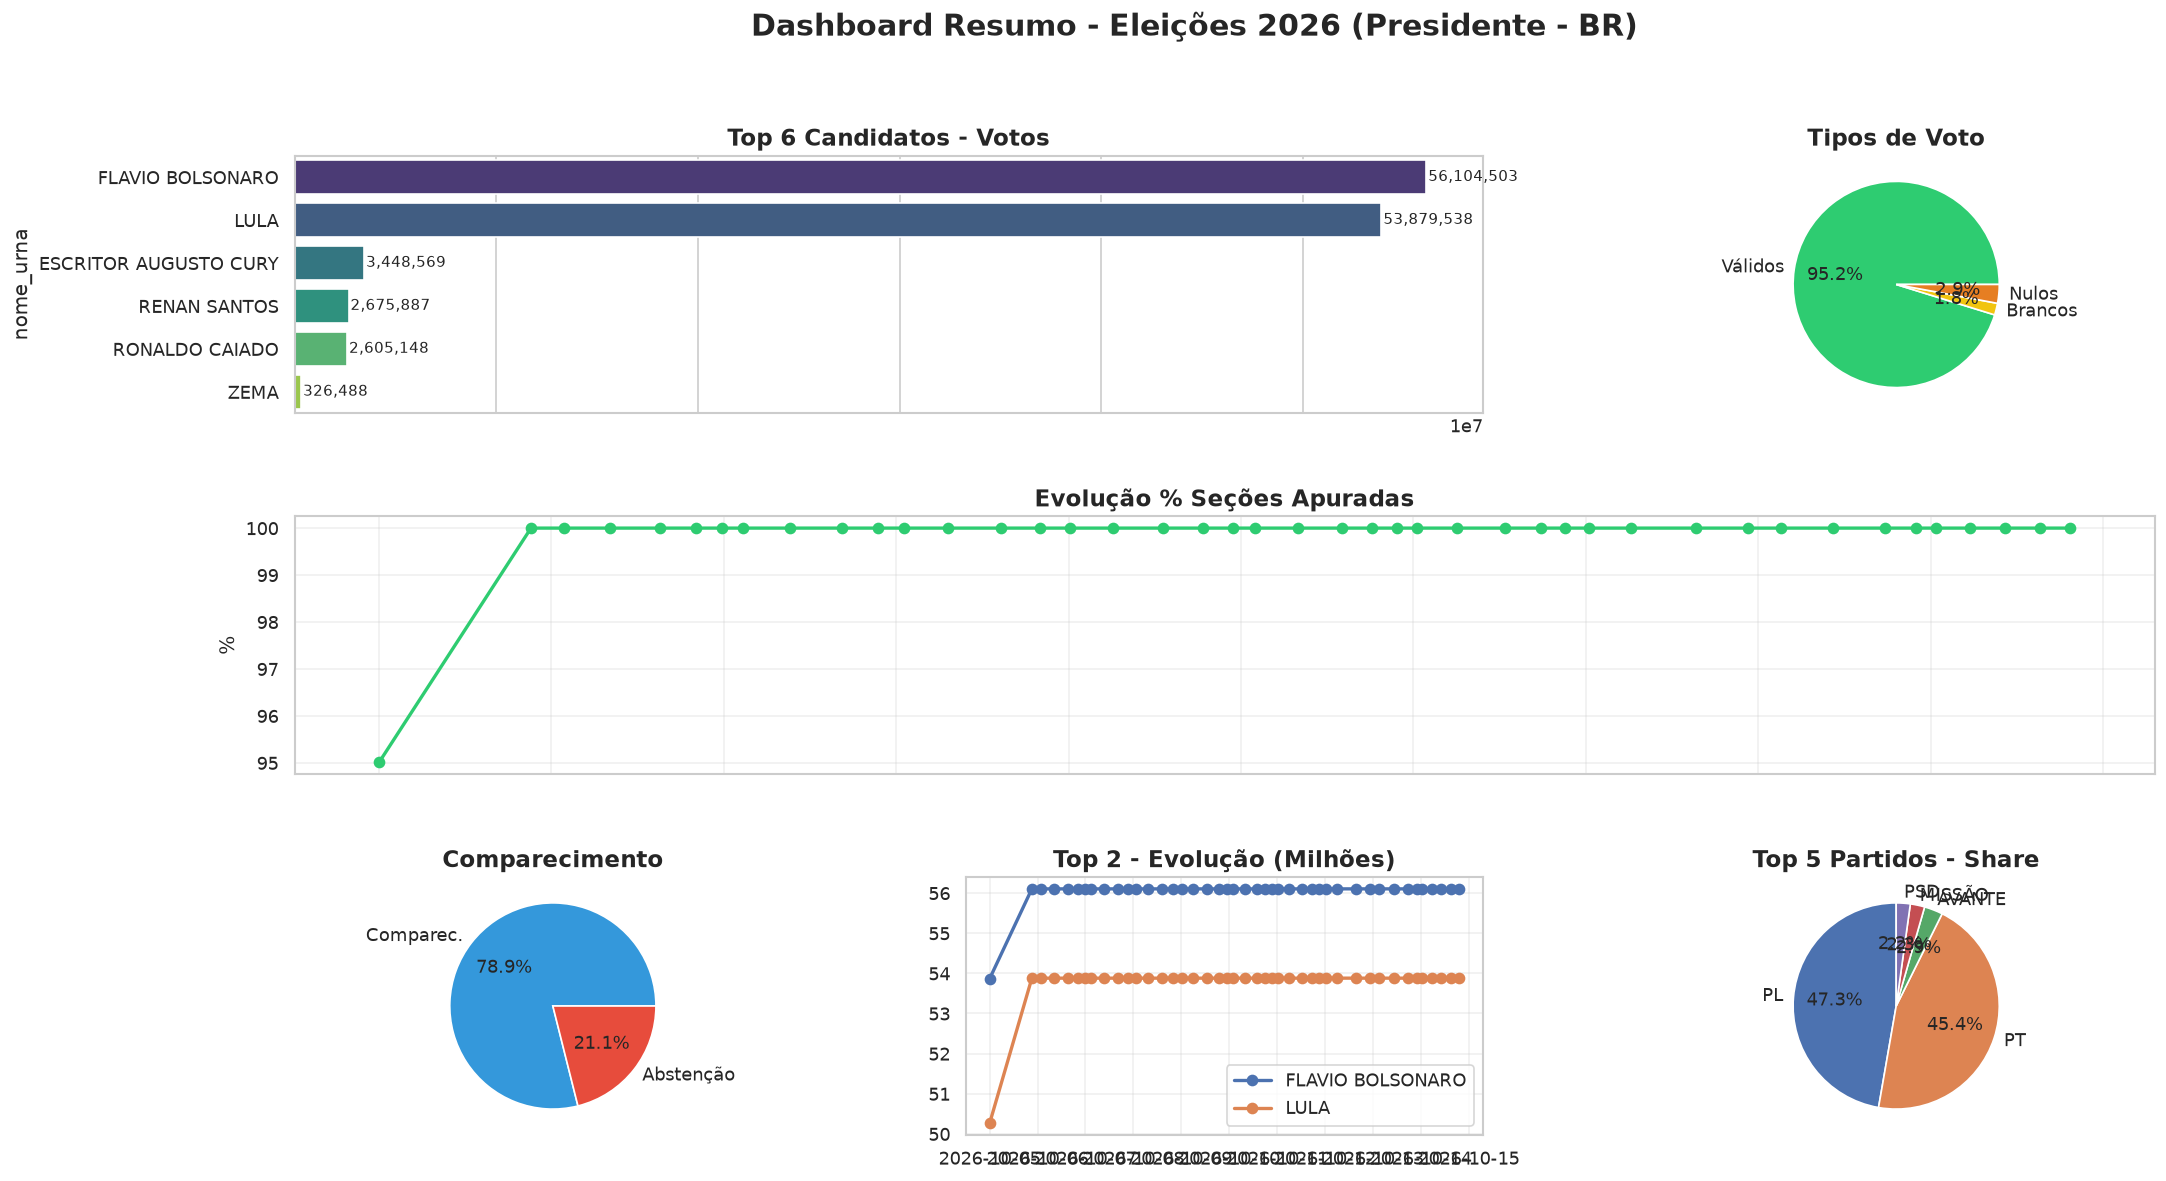

✅ Dashboard gerado e salvo como dashboard_resumo.png (também embutido no ipynb)


In [9]:

fig = plt.figure(figsize=(20, 12))
gs = fig.add_gridspec(3, 3, hspace=0.4, wspace=0.3)

# Top left: barras candidatos
ax1 = fig.add_subplot(gs[0, :2])
df_top = pd.DataFrame(latest['candidatos']).head(6)
sns.barplot(data=df_top, x='votos', y='nome_urna', palette='viridis', ax=ax1)
ax1.set_title('Top 6 Candidatos - Votos', fontweight='bold')
for i, v in enumerate(df_top['votos']):
    ax1.text(v + 100000, i, f"{v:,}", va='center', fontsize=9)

# Top right: pizza tipos voto
ax2 = fig.add_subplot(gs[0, 2])
ax2.pie([latest['votos_validos'], latest['votos_brancos'], latest['votos_nulos']],
        labels=['Válidos','Brancos','Nulos'], autopct='%1.1f%%', colors=['#2ecc71','#f1c40f','#e67e22'])
ax2.set_title('Tipos de Voto', fontweight='bold')

# Middle: timeseries pct apuradas
ax3 = fig.add_subplot(gs[1, :])
df_sec = pd.DataFrame([{'ts': pd.to_datetime(s['scraped_at_utc']), 'pct': s['pct_apuradas']} for s in all_snapshots]).sort_values('ts')
ax3.plot(df_sec['ts'], df_sec['pct'], marker='o', color='#2ecc71', linewidth=2)
ax3.set_title('Evolução % Seções Apuradas', fontweight='bold')
ax3.set_ylabel('%')
ax3.grid(True, alpha=0.3)
fig.autofmt_xdate()

# Bottom left: comparecimento vs abstencao
ax4 = fig.add_subplot(gs[2, 0])
ax4.pie([latest['comparecimento'], latest['abstencao']], labels=['Comparec.','Abstenção'], autopct='%1.1f%%', colors=['#3498db','#e74c3c'])
ax4.set_title('Comparecimento', fontweight='bold')

# Bottom middle: evolução votos top2
ax5 = fig.add_subplot(gs[2, 1])
# Build quick pivot for top2
top2_names = [c['nome_urna'] for c in latest['candidatos'][:2]]
for name in top2_names:
    data = [s for s in all_snapshots]
    ts = [pd.to_datetime(s['scraped_at_utc']) for s in data]
    votos = [next((c['votos'] for c in s['candidatos'] if c['nome_urna']==name), 0)/1e6 for s in data]
    ax5.plot(ts, votos, marker='o', label=name, linewidth=2)
ax5.set_title('Top 2 - Evolução (Milhões)', fontweight='bold')
ax5.legend()
ax5.grid(True, alpha=0.3)

# Bottom right: distribuição partidos
ax6 = fig.add_subplot(gs[2, 2])
df_party = pd.DataFrame(latest['candidatos']).groupby('partido')['votos'].sum().sort_values(ascending=False).head(5)
ax6.pie(df_party.values, labels=df_party.index, autopct='%1.1f%%', startangle=90)
ax6.set_title('Top 5 Partidos - Share', fontweight='bold')

plt.suptitle('Dashboard Resumo - Eleições 2026 (Presidente - BR)', fontsize=18, fontweight='bold', y=0.98)
plt.savefig('dashboard_resumo.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Dashboard gerado e salvo como dashboard_resumo.png (também embutido no ipynb)")
